# 04 · Re-run with the feature set of `python_code/Statistical_Feature_Extraction.ipynb`

Notebooks 02–03 used features I designed. Here every experiment is repeated with **the feature set of the
project's own `Statistical_Feature_Extraction.ipynb`**, computed exactly as there (`sig2features` +
`eda_feature_extraction`). These functions (and `reshape_function`, used for the windows in notebook 01) are now
in **`src/eda_proj/features.py`**, copied unchanged from that notebook, and imported from there:

* **12 descriptives** for each signal: mean, max, std, skew, norm1 (Σ|x|), median, min, range, mean slope
  (mean of first differences), kurtosis, sample entropy and approximate entropy (`nk.entropy_sample`,
  `nk.entropy_approximate`, defaults). Computed for the **raw EDA** (`eda_*`), the **tonic** (`tonic_*`) and the
  **phasic** (`phasic_*`) component.
* **12 phasic SCR/spectral features** (`nk.eda_peaks` on the phasic component): peak count, peak rate, mean / max /
  sum amplitude, mean and std rise time, mean recovery time, mean onset and offset time, rise/recovery ratio, and
  power of the phasic signal in 0.045–0.25 Hz.

→ **`raw` = 12 features**, and **`raw + decomposition` = 48 features** (12 + 12 tonic + 24 phasic), exactly the
48-column `feature_dataframe.csv` of the original notebook.

Only changes from the original code (both in `eda_feature_extraction`; without them the original silently returns
NaN for `eda_symp_power` with current library versions):
* `np.trapz`, removed in NumPy 2.x, falls back to `np.trapezoid`;
* the window is passed to `scipy.signal.welch` as a NumPy array (recent SciPy rejects a pandas row).
* The input is the raw 1-min window in µS, as in notebooks 02–03. The original used min-max-normalised,
  low-pass-filtered whole recordings, and `reshape_function` with a 15 s stride and 80 % label purity; here the
  windows come from the same `reshape_function` with a 10 s stride and 100 % purity (notebook 01).

SCR features are NaN when `eda_peaks` finds no peak, so every classifier gets a **median imputer fitted inside each
training fold**.

Setting: **no per-subject normalisation**, 1-min windows (10 s stride, 100 % purity), LOSO over 15 subjects.
**Every decomposition is applied to each 1-min window on its own.** Decompositions compared: NeuroKit2
`highpass` (default) and `smoothmedian`, sparsEDA, and `gmsEDA` over a 4 × 2 × 2 grid of
`num_of_chops` × `overlap` × `lam_scale`. As an extension that the original feature set does not have, the 12
descriptives are also computed on the **sparse driver** of `gmsEDA` and sparsEDA (`driver_*`, 60 features in total).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings, time, itertools
warnings.filterwarnings("ignore")
from eda_utils import *
pd.set_option("display.width", 220); pd.set_option("display.max_columns", 30)
import neurokit2 as nk
print("neurokit2", nk.__version__)

WINDOWING = "reshape"   # "reshape" (default: eda_proj.features.reshape_function) or "block"; see notebook 01
LABELS = (1, 2)         # WESAD conditions in the task: 1 baseline, 2 stress, 3 amusement, 4 meditation
MERGE = {}              # optional label merging, e.g. {3: 1} = amusement counted with baseline (stress vs non-stress)
STRIDE = 10
# per-window caches (decompositions, features) live in cache/<WINDOWING>/label<k>/ and are combined for LABELS;
# results that depend on the task (screening, nested selection) live in RES:
RES = results_dir(WINDOWING, LABELS, MERGE)
W, meta = load_windows(WINDOWING, LABELS, STRIDE)
y, groups = task_labels(meta, MERGE), meta.subject.values

neurokit2 0.2.13


## 1. Features for every decomposition (cached in `cache/<WINDOWING>/label<k>/origfeat/`)
Each feature table takes about 1 min to compute. Each `gmsEDA` configuration also needs its decomposition
(0.5–3 min).

In [2]:
t0 = time.time()
GRID = list(itertools.product([5, 10, 20, 40], [0.8, 0.9], [1, 3]))
KINDS = ["raw", "nk_highpass", "nk_smoothmedian", "sparsEDA", "sparsEDA_drv"] + \
        [f"gms_c{ch}_o{ov:g}_l{ls:g}{d}" for ch, ov, ls in GRID for d in ["", "_drv"]]
# each table is cached per label in cache/<WINDOWING>/label<k>/origfeat/<kind>.csv (computed only if missing)
F = {k: orig_features(WINDOWING, LABELS, k) for k in KINDS}
print(f"{time.time() - t0:.0f}s;", len(F), "feature tables;", "columns:", F["raw"].shape[1], "/", F["nk_highpass"].shape[1],
      "/", F["gms_c20_o0.9_l1_drv"].shape[1])
print("fraction of windows with no SCR peak found (phasic_peak_count == 0):")
print(pd.Series({k: (v.phasic_peak_count == 0).mean() for k, v in F.items() if "phasic_peak_count" in v}).round(3).to_string())

3s; 37 feature tables; columns: 12 / 48 / 60
fraction of windows with no SCR peak found (phasic_peak_count == 0):
nk_highpass            0.0
nk_smoothmedian        0.0
sparsEDA               0.0
sparsEDA_drv           0.0
gms_c5_o0.8_l1         0.0
gms_c5_o0.8_l1_drv     0.0
gms_c5_o0.8_l3         0.0
gms_c5_o0.8_l3_drv     0.0
gms_c5_o0.9_l1         0.0
gms_c5_o0.9_l1_drv     0.0
gms_c5_o0.9_l3         0.0
gms_c5_o0.9_l3_drv     0.0
gms_c10_o0.8_l1        0.0
gms_c10_o0.8_l1_drv    0.0
gms_c10_o0.8_l3        0.0
gms_c10_o0.8_l3_drv    0.0
gms_c10_o0.9_l1        0.0
gms_c10_o0.9_l1_drv    0.0
gms_c10_o0.9_l3        0.0
gms_c10_o0.9_l3_drv    0.0
gms_c20_o0.8_l1        0.0
gms_c20_o0.8_l1_drv    0.0
gms_c20_o0.8_l3        0.0
gms_c20_o0.8_l3_drv    0.0
gms_c20_o0.9_l1        0.0
gms_c20_o0.9_l1_drv    0.0
gms_c20_o0.9_l3        0.0
gms_c20_o0.9_l3_drv    0.0
gms_c40_o0.8_l1        0.0
gms_c40_o0.8_l1_drv    0.0
gms_c40_o0.8_l3        0.0
gms_c40_o0.8_l3_drv    0.0
gms_c40_o0.9_l1       

## 2. `gmsEDA` parameter grid (screening with LogReg + HistGB)

In [3]:
MODELS = models_with_imputer()
SCREEN = {k: MODELS[k] for k in ["LogReg", "HistGB"]}
rows = []
t0 = time.time()
base = {}
for m, fn in SCREEN.items():
    base[m] = loso_eval(fn, F["raw"].values, y, groups)[0]["acc"]
for ch, ov, ls in GRID:
    tag = f"gms_c{ch}_o{ov:g}_l{ls:g}"
    for drv in ["", "_drv"]:
        for m, fn in SCREEN.items():
            s, _ = loso_eval(fn, F[tag + drv].values, y, groups)
            rows.append(dict(num_of_chops=ch, overlap=ov, lam_scale=ls, driver=bool(drv), model=m, acc=s["acc"]))
print(f"{time.time() - t0:.0f}s;  raw (12 features):", {k: round(v, 3) for k, v in base.items()})
scr = pd.DataFrame(rows)
S = scr.pivot_table(index=["num_of_chops", "overlap", "lam_scale"], columns=["driver", "model"], values="acc")
S[("mean", "no driver")] = S[False].mean(axis=1); S[("mean", "with driver")] = S[True].mean(axis=1)
S.sort_values(("mean", "no driver"), ascending=False).round(3)

321s;  raw (12 features): {'LogReg': 0.771, 'HistGB': 0.792}


driver                          False          True             mean            
model                          HistGB LogReg HistGB LogReg no driver with driver
num_of_chops overlap lam_scale                                                  
10           0.8     1          0.845  0.842  0.853  0.847     0.843       0.850
40           0.8     1          0.842  0.838  0.842  0.852     0.840       0.847
20           0.9     1          0.839  0.835  0.844  0.848     0.837       0.846
10           0.9     1          0.854  0.820  0.877  0.846     0.837       0.862
20           0.8     1          0.847  0.810  0.867  0.850     0.829       0.859
40           0.9     1          0.829  0.808  0.852  0.852     0.818       0.852
5            0.9     1          0.815  0.812  0.819  0.824     0.813       0.822
10           0.9     3          0.837  0.790  0.825  0.791     0.813       0.808
40           0.8     3          0.819  0.803  0.826  0.798     0.811       0.812
20           0.8     3          0.821  0.793  0.819  0.796     0.807       0.808
             0.9     3          0.817  0.795  0.821  0.795     0.806       0.808
10           0.8     3          0.817  0.794  0.814  0.794     0.806       0.804
5            0.8     1          0.803  0.800  0.809  0.785     0.802       0.797
                     3          0.821  0.771  0.821  0.777     0.796       0.799
             0.9     3          0.809  0.774  0.812  0.777     0.792       0.795
40           0.9     3          0.789  0.777  0.828  0.797     0.783       0.813

## 3. Main comparison (4 classifiers, paired per-subject tests vs `raw`)
The `gmsEDA` configurations shown are the old default (5 chops, 0.8, λ 3), the configuration chosen in notebook 02
(20 chops, 0.9, λ 1) and the best one of the screening above. Picking the best of the screen is optimistic;
section 4 gives the unbiased nested estimate.

In [4]:
best_tag = "gms_c%d_o%g_l%g" % S[("mean", "no driver")].idxmax()
best_tag_drv = "gms_c%d_o%g_l%g" % S[("mean", "with driver")].idxmax()
print("best in screen (no driver):", best_tag, "| (with driver):", best_tag_drv)
SETS = {"raw (12)": F["raw"],
        "raw + NeuroKit2 highpass": F["nk_highpass"],
        "raw + NeuroKit2 smoothmedian": F["nk_smoothmedian"],
        "raw + sparsEDA": F["sparsEDA"],
        "raw + gmsEDA c5 o0.8 λ3 (old default)": F["gms_c5_o0.8_l3"],
        "raw + gmsEDA c20 o0.9 λ1 (notebook 02)": F["gms_c20_o0.9_l1"],

        "raw + sparsEDA + driver": F["sparsEDA_drv"],
        "raw + gmsEDA c20 o0.9 λ1 + driver": F["gms_c20_o0.9_l1_drv"],
}
if best_tag != "gms_c20_o0.9_l1":
    SETS[f"raw + gmsEDA {best_tag[4:]} (best in screen)"] = F[best_tag]
if best_tag_drv != "gms_c20_o0.9_l1":
    SETS[f"raw + gmsEDA {best_tag_drv[4:]} + driver (best in screen)"] = F[best_tag_drv + "_drv"]
t0 = time.time()
res, ptab = compare_feature_sets(SETS, y, groups, models=MODELS, baseline="raw (12)")
print(f"{time.time() - t0:.0f}s")
acc = res.pivot(index="features", columns="model", values="acc").loc[list(SETS)]
acc["mean"] = acc.mean(axis=1)
acc.round(3)

best in screen (no driver): gms_c10_o0.8_l1 | (with driver): gms_c10_o0.9_l1
360s


model,HistGB,LogReg,RandomForest,SVM-RBF,mean
features,,,,,
raw (12),0.792,0.771,0.740,0.776,0.770
raw + NeuroKit2 highpass,0.877,0.836,0.868,0.887,0.867
raw + NeuroKit2 smoothmedian,0.855,0.832,0.860,0.857,0.851
raw + sparsEDA,0.827,0.847,0.846,0.865,0.846
raw + gmsEDA c5 o0.8 λ3 (old default),0.821,0.771,0.750,0.816,0.789
raw + gmsEDA c20 o0.9 λ1 (notebook 02),0.839,0.835,0.823,0.871,0.842
raw + sparsEDA + driver,0.828,0.843,0.849,0.861,0.845
raw + gmsEDA c20 o0.9 λ1 + driver,0.844,0.848,0.839,0.890,0.855
raw + gmsEDA c10_o0.8_l1 (best in screen),0.845,0.842,0.830,0.877,0.848


In [5]:
f1 = res.pivot(index="features", columns="model", values="f1").loc[list(SETS)]
f1["mean"] = f1.mean(axis=1)
f1.round(3)

model,HistGB,LogReg,RandomForest,SVM-RBF,mean
features,,,,,
raw (12),0.772,0.726,0.721,0.734,0.738
raw + NeuroKit2 highpass,0.862,0.812,0.853,0.871,0.850
raw + NeuroKit2 smoothmedian,0.836,0.807,0.844,0.836,0.831
raw + sparsEDA,0.804,0.824,0.828,0.844,0.825
raw + gmsEDA c5 o0.8 λ3 (old default),0.802,0.728,0.732,0.791,0.763
raw + gmsEDA c20 o0.9 λ1 (notebook 02),0.824,0.809,0.807,0.853,0.823
raw + sparsEDA + driver,0.804,0.820,0.832,0.840,0.824
raw + gmsEDA c20 o0.9 λ1 + driver,0.828,0.826,0.823,0.875,0.838
raw + gmsEDA c10_o0.8_l1 (best in screen),0.829,0.818,0.815,0.860,0.831


In [6]:
ptab.assign(cell=lambda d: d.apply(lambda r: f"{r.delta:+.3f} ({r.wins}/{r.losses}, p={r.p:.3f})", axis=1)) \
    .pivot(index="features", columns="model", values="cell").loc[list(SETS)[1:]]

model,HistGB,LogReg,RandomForest,SVM-RBF
features,,,,
raw + NeuroKit2 highpass,"+0.085 (14/0, p=0.001)","+0.066 (14/1, p=0.000)","+0.128 (13/1, p=0.002)","+0.110 (14/0, p=0.001)"
raw + NeuroKit2 smoothmedian,"+0.063 (14/0, p=0.001)","+0.061 (11/2, p=0.004)","+0.120 (12/2, p=0.002)","+0.081 (14/1, p=0.000)"
raw + sparsEDA,"+0.035 (9/2, p=0.021)","+0.077 (13/2, p=0.001)","+0.105 (13/1, p=0.002)","+0.088 (14/1, p=0.000)"
raw + gmsEDA c5 o0.8 λ3 (old default),"+0.028 (10/2, p=0.028)","+0.000 (7/7, p=0.975)","+0.010 (8/4, p=0.347)","+0.040 (9/5, p=0.149)"
raw + gmsEDA c20 o0.9 λ1 (notebook 02),"+0.047 (10/3, p=0.016)","+0.064 (12/2, p=0.002)","+0.084 (12/1, p=0.005)","+0.095 (14/0, p=0.001)"
raw + sparsEDA + driver,"+0.035 (12/2, p=0.003)","+0.073 (13/2, p=0.001)","+0.109 (12/2, p=0.002)","+0.084 (13/1, p=0.002)"
raw + gmsEDA c20 o0.9 λ1 + driver,"+0.053 (12/2, p=0.011)","+0.078 (13/2, p=0.005)","+0.100 (12/1, p=0.004)","+0.113 (14/0, p=0.001)"
raw + gmsEDA c10_o0.8_l1 (best in screen),"+0.053 (13/1, p=0.004)","+0.071 (11/3, p=0.004)","+0.090 (13/1, p=0.002)","+0.100 (15/0, p=0.000)"
raw + gmsEDA c10_o0.9_l1 + driver (best in screen),"+0.085 (14/0, p=0.001)","+0.076 (14/1, p=0.001)","+0.119 (14/0, p=0.001)","+0.103 (14/1, p=0.000)"


### Head-to-head: `gmsEDA` against the best non-`gmsEDA` decomposition
Rows without `+ driver` use the same 48 features as the reference. Rows with `+ driver` add the 12 driver
descriptives (60 features), which NeuroKit2 highpass cannot provide.

In [7]:
others = ["raw + NeuroKit2 highpass", "raw + NeuroKit2 smoothmedian", "raw + sparsEDA"]
best_other = max(others, key=lambda k: acc.loc[k, "mean"])
cands = [k for k in SETS if "gmsEDA" in k]
_, h2h = compare_feature_sets({best_other: SETS[best_other], **{k: SETS[k] for k in cands}},
                              y, groups, models=MODELS, baseline=best_other)
print("reference:", best_other)
h2h.pivot(index="features", columns="model", values="delta").round(3).join(
    h2h.pivot(index="features", columns="model", values="p").round(3), lsuffix=" Δ", rsuffix=" p")

reference: raw + NeuroKit2 highpass


model,HistGB Δ,LogReg Δ,RandomForest Δ,SVM-RBF Δ,HistGB p,LogReg p,RandomForest p,SVM-RBF p
features,,,,,,,,
raw + gmsEDA c10_o0.8_l1 (best in screen),-0.032,0.005,-0.037,-0.010,0.011,0.861,0.026,0.221
raw + gmsEDA c10_o0.9_l1 + driver (best in screen),0.000,0.010,-0.008,-0.007,0.917,0.826,0.722,0.397
raw + gmsEDA c20 o0.9 λ1 (notebook 02),-0.038,-0.001,-0.043,-0.015,0.152,0.451,0.463,0.272
raw + gmsEDA c20 o0.9 λ1 + driver,-0.032,0.012,-0.028,0.003,0.173,0.975,0.937,0.861
raw + gmsEDA c5 o0.8 λ3 (old default),-0.057,-0.066,-0.118,-0.070,0.004,0.000,0.003,0.003


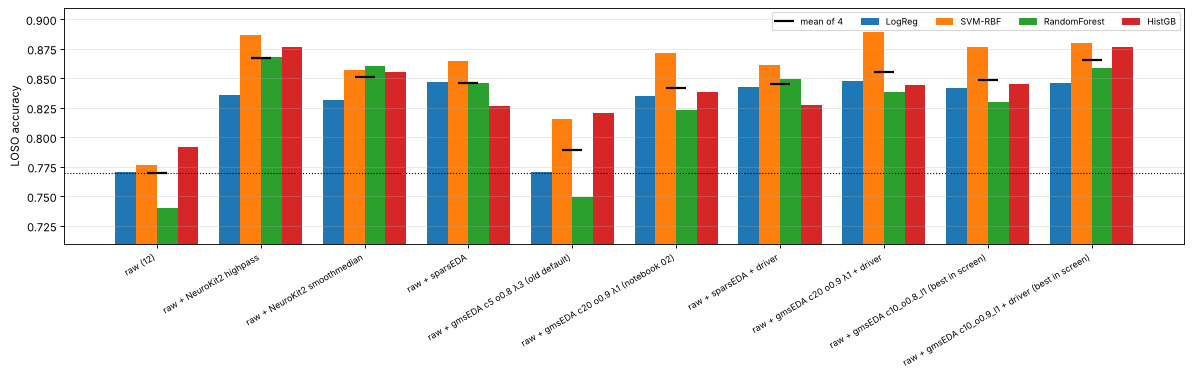

In [8]:
fig, ax = plt.subplots(figsize=(15, 4.8))
order = list(SETS); xs = np.arange(len(order))
for j, m in enumerate(["LogReg", "SVM-RBF", "RandomForest", "HistGB"]):
    ax.bar(xs + (j - 1.5) * 0.2, acc.loc[order, m].values, width=0.2, label=m)
ax.plot(xs, acc.loc[order, "mean"].values, "k_", ms=18, mew=2, label="mean of 4")
ax.axhline(acc.loc["raw (12)", "mean"], color="k", ls=":", lw=1)
ax.set_xticks(xs); ax.set_xticklabels(order, rotation=30, ha="right", fontsize=8)
lo = acc[["LogReg", "SVM-RBF", "RandomForest", "HistGB"]].values.min()
ax.set_ylim(lo - 0.03, acc.values.max() + 0.02); ax.set_ylabel("LOSO accuracy"); ax.legend(fontsize=8, ncol=5); ax.grid(axis="y", alpha=.3)
plt.tight_layout(); plt.show()

## 4. Nested LOSO: is choosing a `gmsEDA` configuration still worth it?
For each held-out subject, the candidate is chosen by inner 5-fold group CV (LogReg) on the other 14 subjects from:
raw only, the three standard decompositions, and the 16 `gmsEDA` configurations (all without driver features, so all
use the original 48-feature set). It is then refit with LogReg and HistGB.

In [9]:
CANDS = {"raw": F["raw"], "nk_highpass": F["nk_highpass"], "nk_smoothmedian": F["nk_smoothmedian"], "sparsEDA": F["sparsEDA"]}
CANDS.update({f"gms_c{ch}_o{ov:g}_l{ls:g}": F[f"gms_c{ch}_o{ov:g}_l{ls:g}"] for ch, ov, ls in GRID})
t0 = time.time()
nest, chosen = nested_select_loso(CANDS, y, groups, MODELS["LogReg"], {k: MODELS[k] for k in ["LogReg", "HistGB"]})
print(f"{time.time() - t0:.0f}s")
print(chosen.chosen.value_counts().to_string())
nest.round(3)

67s
chosen
sparsEDA           6
gms_c10_o0.8_l1    4
nk_highpass        3
gms_c20_o0.9_l1    1
gms_c40_o0.8_l1    1


,acc,f1
LogReg,0.814,0.786
HistGB,0.833,0.812


## Conclusion

*(The numbers below are for the default `LABELS = (1, 2)`, baseline vs stress. Notebook 05 covers stress vs
non-stress and the 3-class task with amusement.)*

**With the original feature set, `gmsEDA` is no better than NeuroKit2's default decomposition.** Mean LOSO
accuracy over 4 classifiers (1-min windows from `reshape_function`, no per-subject normalisation):

| features | # | mean acc | Δ vs raw |
|---|---|---|---|
| raw (eda_* descriptives) | 12 | 0.770 | – |
| raw + gmsEDA, old default (5 chops, 0.8, λ 3) | 48 | 0.789 | +0.019 |
| raw + gmsEDA (20 chops, 0.9, λ 1; chosen in notebook 02) | 48 | 0.842 | +0.072 |
| raw + sparsEDA | 48 | 0.846 | +0.076 |
| raw + gmsEDA (10 chops, 0.8, λ 1; best in this screen) | 48 | 0.848 | +0.078 |
| raw + NeuroKit2 smoothmedian | 48 | 0.851 | +0.081 |
| raw + gmsEDA (20, 0.9, λ 1) + driver descriptives | 60 | 0.855 | +0.085 |
| raw + gmsEDA (10, 0.9, λ 1; best in screen) + driver descriptives | 60 | 0.865 | +0.095 |
| **raw + NeuroKit2 highpass (default)** | 48 | **0.867** | **+0.097** |

* **Every decomposition helps a lot** compared with the 12 raw descriptives: +7 to +10 points on average, 10–15 of
  15 subjects, p ≤ 0.02. The exception is `gmsEDA` with its old defaults (+1.9 points, significant only for HistGB). With this
  feature set the phasic SCR features from `nk.eda_peaks` carry much of the information, whichever method produced
  the phasic part.
* **`gmsEDA` vs NeuroKit2 highpass:** with the same 48 features, the tuned `gmsEDA` is *behind* (−4.3 to +0.5
  points; significant only for HistGB/RF with the 10-chop configuration, p = 0.01–0.03). With the 12 driver
  descriptives it is level (−3.3 to +1.2 points, p ≥ 0.17). The old defaults are significantly worse than NeuroKit2
  (−6 to −12 points, p ≤ 0.004).
* **Parameters:** λ-scale 1 is best for every chop/overlap setting (all top 7 configurations); 10–40 chops with
  overlap 0.8–0.9 are close together.
* **Nested LOSO:** choosing among raw, NeuroKit2, sparsEDA and 16 `gmsEDA` configurations inside each fold picks
  sparsEDA in 6 folds, a `gmsEDA` configuration in 6 and NeuroKit2 highpass in 3. It reaches 0.814 (LogReg) /
  0.833 (HistGB), which is no better than simply using NeuroKit2 highpass (0.836 / 0.877).

**Taken together with notebooks 02–03:** whether `gmsEDA` beats the standard decompositions depends on the features.
With the features of notebooks 02–03 (which include event counts of the sparse driver) `gmsEDA` was best
(0.866 vs 0.846 for NeuroKit2 highpass). With the project's original feature set (descriptives + `eda_peaks` SCR
features on the phasic part) NeuroKit2's simple high-pass split is at least as good (0.867), and the tuned
`gmsEDA` is only competitive when its driver is also described (0.865). The highest no-normalisation accuracy is
about the same for both feature sets (≈ 0.87). The same conclusions held with block-aligned windows
(`WINDOWING = "block"`: NeuroKit2 highpass 0.863, `gmsEDA` 0.854, `gmsEDA` + driver 0.868).